# Exploración y KPIs — Madrid Pádel
Borja Ibáñez Pérez · ICAI


In [1]:
from pathlib import Path
import pandas as pd

carpeta_datos = Path("Datos/procesados")
carpeta_analisis = Path("Datos/analisis")
carpeta_analisis.mkdir(parents=True, exist_ok=True)

archivo = carpeta_datos / "reservas_individuales_amplias.csv"

reservas = pd.read_csv(
    archivo,
    encoding="utf-8-sig",
    parse_dates=["fecha"]
)

reservas["anio"] = reservas["fecha"].dt.year.astype("Int64")
reservas["mes"] = reservas["fecha"].dt.to_period("M").astype("string")

print("Registros:", len(reservas))
print("Nombres de centro antes de normalizar:", reservas["Centro deportivo"].nunique())

print("\nReservas por año:")
print(reservas.groupby("anio").size())

print("\nPrimera fecha:", reservas["fecha"].min())
print("Última fecha:", reservas["fecha"].max())

Registros: 719178
Nombres de centro antes de normalizar: 48

Reservas por año:
anio
2024    252954
2025    256122
2026    210102
dtype: int64

Primera fecha: 2024-01-02 00:00:00
Última fecha: 2026-10-31 00:00:00


In [2]:
# Cargar todos los tipos de uso de pádel aceptados y validados.
usos_padel = pd.read_csv(
    carpeta_datos / "padel_validos.csv",
    encoding="utf-8-sig",
    parse_dates=["fecha"]
)



In [3]:
# Unificar el formato y las variantes de nombres de centros.
# Conservamos el nombre original para documentar los cambios.

equivalencias_centros = {
    "CDM El Quijote": "El Quijote"
}

for tabla in [reservas, usos_padel]:

    if "centro_nombre_original" not in tabla.columns:
        tabla["centro_nombre_original"] = tabla["Centro deportivo"]

    tabla["Centro deportivo"] = (
        tabla["centro_nombre_original"]
        .astype("string")
        .str.normalize("NFC")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .replace(equivalencias_centros)
    )

# Mostrar los nombres que han cambiado
cambios_nombres = (
    usos_padel[["centro_nombre_original", "Centro deportivo"]]
    .drop_duplicates()
)

cambios_nombres = cambios_nombres.loc[
    cambios_nombres["centro_nombre_original"]
    != cambios_nombres["Centro deportivo"]
].copy()

cambios_nombres["original_visible"] = (
    cambios_nombres["centro_nombre_original"].map(repr)
)

display(
    cambios_nombres[["original_visible", "Centro deportivo"]]
)

print("Nombres distintos antes:",
      reservas["centro_nombre_original"].nunique())

print("Nombres distintos después:",
      reservas["Centro deportivo"].nunique())

print("Registros individuales conservados:", len(reservas))

# Guardar las equivalencias aplicadas
cambios_nombres[
    ["centro_nombre_original", "Centro deportivo"]
].to_csv(
    carpeta_analisis / "normalizacion_centros.csv",
    index=False,
    encoding="utf-8-sig"
)

,original_visible,Centro deportivo
683595,' Daoíz y Velarde',Daoíz y Velarde
683607,' Entrevias',Entrevias
684443,'CDM El Quijote',El Quijote


Nombres distintos antes: 48
Nombres distintos después: 45
Registros individuales conservados: 719178


Se normalizaron los nombres de los centros eliminando espacios sobrantes y unificando «CDM El Quijote» como «El Quijote».
Esta equivalencia se adoptó al observar unidades deportivas coincidentes y periodos mensuales complementarios entre ambas denominaciones. Se conservaron los nombres originales y no se eliminaron registros por esta operación.

## Cobertura mensual tras normalizar

In [4]:
cobertura_mensual = (
    reservas.groupby(
        ["Centro deportivo", "mes"],
        as_index=False
    )
    .agg(
        reservas=("fecha", "size"),
        dias_con_registros=("fecha", "nunique"),
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max")
    )
    .sort_values(["Centro deportivo", "mes"])
)

display(cobertura_mensual.head(20))

,Centro deportivo,mes,reservas,dias_con_registros,primera_fecha,ultima_fecha
0,Adelfas,2024-01,157,30,2024-01-02,2024-01-31
1,Adelfas,2024-02,155,29,2024-02-01,2024-02-29
2,Adelfas,2024-03,145,31,2024-03-01,2024-03-31
3,Adelfas,2024-04,182,30,2024-04-01,2024-04-30
4,Adelfas,2024-05,183,30,2024-05-02,2024-05-31
5,Adelfas,2024-06,176,30,2024-06-01,2024-06-30
6,Adelfas,2024-07,123,30,2024-07-01,2024-07-30
7,Adelfas,2024-09,162,29,2024-09-02,2024-09-30
8,Adelfas,2024-10,155,31,2024-10-01,2024-10-31
9,Adelfas,2024-11,171,29,2024-11-01,2024-11-30


In [5]:
# Todos los meses comprendidos entre las fechas del conjunto.
meses = pd.period_range(
    start=reservas["fecha"].min(),
    end=reservas["fecha"].max(),
    freq="M"
).astype(str)

tabla_meses = cobertura_mensual.pivot(
    index="Centro deportivo",
    columns="mes",
    values="reservas"
).reindex(columns=meses)

display(tabla_meses)

# Centros que tienen al menos un mes sin registros individuales.
centros_a_revisar = tabla_meses.loc[
    tabla_meses.isna().any(axis=1)
]

print("Centros con algún mes sin registros:", len(centros_a_revisar))
display(centros_a_revisar)

,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
Centro deportivo,,,,,,,,,,,,,,,,,,,,,
Adelfas,157.0,155.0,145.0,182.0,183.0,176.0,123.0,NaN,162.0,155.0,...,116.0,122.0,125.0,215.0,186.0,153.0,123.0,NaN,179.0,181.0
Alfredo Goyeneche,262.0,339.0,260.0,418.0,433.0,438.0,307.0,NaN,406.0,428.0,...,255.0,303.0,460.0,419.0,403.0,458.0,NaN,NaN,NaN,NaN
Aluche,190.0,252.0,239.0,371.0,345.0,314.0,240.0,249.0,324.0,349.0,...,213.0,194.0,361.0,382.0,306.0,271.0,137.0,252.0,301.0,301.0
Barajas,190.0,226.0,233.0,204.0,220.0,226.0,234.0,132.0,256.0,267.0,...,617.0,652.0,749.0,749.0,771.0,628.0,538.0,548.0,630.0,644.0
Blanca Fernández Ochoa,398.0,514.0,609.0,599.0,624.0,676.0,488.0,480.0,682.0,720.0,...,803.0,768.0,772.0,812.0,843.0,722.0,552.0,797.0,867.0,851.0
Centro Integrado Arganzuela,562.0,668.0,595.0,679.0,643.0,623.0,359.0,NaN,665.0,631.0,...,424.0,546.0,863.0,850.0,726.0,579.0,364.0,NaN,685.0,780.0
Cerro Almodóvar,570.0,536.0,545.0,567.0,460.0,583.0,422.0,167.0,599.0,603.0,...,301.0,274.0,358.0,392.0,477.0,364.0,362.0,251.0,436.0,742.0
Concepción,283.0,308.0,326.0,370.0,372.0,335.0,225.0,307.0,361.0,305.0,...,196.0,198.0,358.0,444.0,337.0,249.0,301.0,353.0,308.0,323.0
Daoíz y Velarde,248.0,286.0,257.0,309.0,301.0,241.0,157.0,NaN,276.0,291.0,...,263.0,256.0,323.0,340.0,259.0,196.0,157.0,NaN,276.0,315.0


Centros con algún mes sin registros: 22


,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
Centro deportivo,,,,,,,,,,,,,,,,,,,,,
Adelfas,157.0,155.0,145.0,182.0,183.0,176.0,123.0,NaN,162.0,155.0,...,116.0,122.0,125.0,215.0,186.0,153.0,123.0,NaN,179.0,181.0
Alfredo Goyeneche,262.0,339.0,260.0,418.0,433.0,438.0,307.0,NaN,406.0,428.0,...,255.0,303.0,460.0,419.0,403.0,458.0,NaN,NaN,NaN,NaN
Centro Integrado Arganzuela,562.0,668.0,595.0,679.0,643.0,623.0,359.0,NaN,665.0,631.0,...,424.0,546.0,863.0,850.0,726.0,579.0,364.0,NaN,685.0,780.0
Daoíz y Velarde,248.0,286.0,257.0,309.0,301.0,241.0,157.0,NaN,276.0,291.0,...,263.0,256.0,323.0,340.0,259.0,196.0,157.0,NaN,276.0,315.0
Eva Duarte,323.0,377.0,334.0,358.0,421.0,389.0,373.0,NaN,477.0,445.0,...,304.0,289.0,463.0,538.0,480.0,345.0,371.0,NaN,498.0,508.0
Fernando Martín,565.0,632.0,600.0,708.0,727.0,547.0,429.0,NaN,631.0,663.0,...,480.0,457.0,745.0,825.0,708.0,544.0,234.0,NaN,NaN,NaN
Francisco Fernández Ochoa,297.0,272.0,257.0,374.0,331.0,295.0,229.0,267.0,349.0,266.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.0
Gallur,881.0,1082.0,1005.0,1309.0,1327.0,1123.0,656.0,NaN,1244.0,1297.0,...,607.0,763.0,1268.0,1352.0,1207.0,1119.0,624.0,NaN,1242.0,1158.0
Gimnasio Moscardó,NaN,NaN,NaN,210.0,272.0,299.0,136.0,NaN,163.0,119.0,...,90.0,122.0,204.0,229.0,205.0,182.0,152.0,NaN,187.0,209.0


In [6]:
cobertura_mensual.to_csv(
    carpeta_analisis / "cobertura_mensual.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_meses.to_csv(
    carpeta_analisis / "reservas_por_centro_y_mes.csv",
    encoding="utf-8-sig"
)

caso_samaranch = cobertura_mensual.loc[
    cobertura_mensual["Centro deportivo"]
    .str.contains("Samaranch", case=False, na=False)
]

display(caso_samaranch)

,Centro deportivo,mes,reservas,dias_con_registros,primera_fecha,ultima_fecha
962,Marqués de Samaranch,2024-01,900,29,2024-01-02,2024-01-31
963,Marqués de Samaranch,2024-02,961,29,2024-02-01,2024-02-29
964,Marqués de Samaranch,2024-03,1064,29,2024-03-01,2024-03-31
965,Marqués de Samaranch,2024-04,999,30,2024-04-01,2024-04-30
966,Marqués de Samaranch,2024-05,918,28,2024-05-03,2024-05-31
967,Marqués de Samaranch,2024-06,1137,30,2024-06-01,2024-06-30
968,Marqués de Samaranch,2024-07,918,30,2024-07-01,2024-07-31
969,Marqués de Samaranch,2024-09,1013,29,2024-09-02,2024-09-30
970,Marqués de Samaranch,2024-10,1078,30,2024-10-01,2024-10-31
971,Marqués de Samaranch,2024-11,990,28,2024-11-02,2024-11-30


In [7]:
# Seleccionar Samaranch.
samaranch = usos_padel.loc[
    usos_padel["Centro deportivo"].str.contains(
        "Samaranch", case=False, na=False
    )
].copy()

samaranch["mes"] = samaranch["fecha"].dt.to_period("M").astype("string")

# Contar registros de cada tipo por mes.
resumen_samaranch = (
    samaranch.groupby(["mes", "Tipo de ocupación"])
    .size()
    .unstack("Tipo de ocupación")
)

# Incluir todos los meses, aunque no tengan registros.
meses_revision = pd.period_range(
    reservas["fecha"].min(), reservas["fecha"].max(), freq="M"
).astype(str)

resumen_samaranch = resumen_samaranch.reindex(meses_revision)

display(resumen_samaranch)

Tipo de ocupación,Reserva Individual,Reserva Interna Individual,Reserva Interna de Temporada,Reserva de Escuela,Reserva de Temporada
2024-01,900.0,6.0,NaN,356.0,38.0
2024-02,961.0,NaN,NaN,387.0,36.0
2024-03,1064.0,NaN,NaN,374.0,48.0
2024-04,999.0,NaN,NaN,407.0,51.0
2024-05,918.0,2.0,NaN,381.0,38.0
2024-06,1137.0,11.0,NaN,257.0,48.0
2024-07,918.0,NaN,NaN,30.0,170.0
2024-08,NaN,NaN,NaN,NaN,NaN
2024-09,1013.0,16.0,NaN,206.0,NaN
2024-10,1078.0,7.0,NaN,420.0,20.0


In [8]:
# 1. Preparar el mes en las dos tablas.
reservas["mes"] = reservas["fecha"].dt.to_period("M").astype(str)
usos_padel["mes"] = usos_padel["fecha"].dt.to_period("M").astype(str)

# 2. Crear todas las combinaciones de centro y mes.
centros = sorted(reservas["Centro deportivo"].dropna().unique())

meses = pd.period_range(
    reservas["fecha"].min(),
    reservas["fecha"].max(),
    freq="M"
).astype(str)

indice = pd.MultiIndex.from_product(
    [centros, meses],
    names=["Centro deportivo", "mes"]
)

# 3. Contar registros individuales y registros de todos los usos.
individuales = reservas.groupby(
    ["Centro deportivo", "mes"]
).size()

todos_usos = usos_padel.groupby(
    ["Centro deportivo", "mes"]
).size()

# Aquí el cero significa "cero registros encontrados en el archivo".
# No confirma que hubiera cero actividad real.
revision_cobertura = pd.DataFrame(index=indice)

revision_cobertura["registros_individuales"] = (
    individuales.reindex(indice, fill_value=0)
)

revision_cobertura["registros_todos_usos"] = (
    todos_usos.reindex(indice, fill_value=0)
)

revision_cobertura = revision_cobertura.reset_index()

# 4. Clasificar cada combinación.
revision_cobertura["situacion"] = "Con registros individuales"

sin_individuales = revision_cobertura["registros_individuales"].eq(0)
sin_ningun_uso = revision_cobertura["registros_todos_usos"].eq(0)

revision_cobertura.loc[
    sin_individuales & ~sin_ningun_uso, "situacion"
] = "Sin individuales, pero con otros usos de pádel"

revision_cobertura.loc[
    sin_ningun_uso, "situacion"
] = "Sin registros de pádel de ningún tipo"

# 5. Mostrar los meses que requieren atención.
meses_a_revisar = revision_cobertura.loc[
    sin_individuales
].copy()

print("Centros analizados:", len(centros))
print("Combinaciones centro-mes:", len(revision_cobertura))

print("\nResumen:")
print(revision_cobertura["situacion"].value_counts())

display(meses_a_revisar)

# 6. Guardar el resultado.
revision_cobertura.to_csv(
    carpeta_analisis / "revision_cobertura_centro_mes.csv",
    index=False,
    encoding="utf-8-sig"
)

Centros analizados: 45
Combinaciones centro-mes: 1530

Resumen:
situacion
Con registros individuales                        1408
Sin registros de pádel de ningún tipo              102
Sin individuales, pero con otros usos de pádel      20
Name: count, dtype: int64


,Centro deportivo,mes,registros_individuales,registros_todos_usos,situacion
7,Adelfas,2024-08,0,0,Sin registros de pádel de ningún tipo
19,Adelfas,2025-08,0,0,Sin registros de pádel de ningún tipo
20,Adelfas,2025-09,0,0,Sin registros de pádel de ningún tipo
21,Adelfas,2025-10,0,0,Sin registros de pádel de ningún tipo
31,Adelfas,2026-08,0,0,Sin registros de pádel de ningún tipo
...,...,...,...,...,...
1494,Victoria Hernández,2026-09,0,0,Sin registros de pádel de ningún tipo
1495,Victoria Hernández,2026-10,0,0,Sin registros de pádel de ningún tipo
1503,Wilfred Agbonavbare,2024-08,0,0,Sin registros de pádel de ningún tipo
1515,Wilfred Agbonavbare,2025-08,0,0,Sin registros de pádel de ningún tipo


In [9]:
revision_cobertura["anio"] = (
    revision_cobertura["mes"].str[:4].astype(int)
)

resumen_centro_anio = (
    revision_cobertura
    .assign(
        con_individuales=lambda x: x["registros_individuales"] > 0,
        con_algun_uso=lambda x: x["registros_todos_usos"] > 0
    )
    .groupby(["Centro deportivo", "anio"], as_index=False)
    .agg(
        meses_analizados=("mes", "size"),
        meses_con_individuales=("con_individuales", "sum"),
        meses_con_algun_uso=("con_algun_uso", "sum"),
        reservas_registradas=("registros_individuales", "sum")
    )
)

resumen_centro_anio["meses_sin_ningun_uso"] = (
    resumen_centro_anio["meses_analizados"]
    - resumen_centro_anio["meses_con_algun_uso"]
)

# Mostrar solo centros que tienen algún mes sin reservas individuales.
centros_con_huecos = meses_a_revisar["Centro deportivo"].unique()

display(
    resumen_centro_anio.loc[
        resumen_centro_anio["Centro deportivo"].isin(centros_con_huecos)
    ].sort_values(["Centro deportivo", "anio"])
)

resumen_centro_anio.to_csv(
    carpeta_analisis / "resumen_cobertura_por_centro_y_anio.csv",
    index=False,
    encoding="utf-8-sig"
)

,Centro deportivo,anio,meses_analizados,meses_con_individuales,meses_con_algun_uso,reservas_registradas,meses_sin_ningun_uso
0,Adelfas,2024,12,11,11,1777,1
1,Adelfas,2025,12,9,9,1146,3
2,Adelfas,2026,10,9,9,1400,1
3,Alfredo Goyeneche,2024,12,11,11,4126,1
4,Alfredo Goyeneche,2025,12,11,11,4296,1
...,...,...,...,...,...,...,...
130,Victoria Hernández,2025,12,7,7,879,5
131,Victoria Hernández,2026,10,0,0,0,10
132,Wilfred Agbonavbare,2024,12,11,11,4341,1
133,Wilfred Agbonavbare,2025,12,11,11,3838,1


## Evidencia de la equivalencia de El Quijote

In [10]:
# Revisar las denominaciones de origen sin alterar los nombres normalizados.
nombres_origen = (usos_padel["centro_nombre_original"].astype("string")
                  .str.normalize("NFC").str.replace(r"\s+", " ", regex=True).str.strip())
quijote = usos_padel.loc[nombres_origen.isin(["CDM El Quijote", "El Quijote"])].copy()
quijote["Centro deportivo"] = nombres_origen.loc[quijote.index]
quijote["mes"] = quijote["fecha"].dt.to_period("M").astype(str)


# Comparar las unidades deportivas de cada denominación.
unidades_quijote = (
    quijote
    .groupby(
        ["Centro deportivo", "Unidad deportiva"],
        dropna=False
    )
    .size()
    .reset_index(name="registros")
)

print("UNIDADES DEPORTIVAS POR NOMBRE DEL CENTRO")
display(unidades_quijote)

# 2. Registros mensuales de todos los tipos de ocupación
meses_quijote = (
    quijote
    .groupby(["mes", "Centro deportivo"])
    .size()
    .unstack("Centro deportivo", fill_value=0)
    .sort_index()
)

print("\nREGISTROS POR MES Y NOMBRE DEL CENTRO")
display(meses_quijote)

# 3. Primera y última fecha con cada denominación
fechas_quijote = (
    quijote
    .groupby("Centro deportivo")
    .agg(
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max"),
        registros=("fecha", "size")
    )
)

print("\nINTERVALO DE FECHAS DE CADA DENOMINACIÓN")
display(fechas_quijote)

UNIDADES DEPORTIVAS POR NOMBRE DEL CENTRO


,Centro deportivo,Unidad deportiva,registros
0,CDM El Quijote,Pista 1 El Quijote,394
1,CDM El Quijote,Pista 2 El Quijote,438
2,CDM El Quijote,Pista 3 El Quijote,431
3,CDM El Quijote,Pista 4 El Quijote,322
4,CDM El Quijote,Pista Prueba Nivel El Quijote,27
5,El Quijote,Pista 1 El Quijote,5395
6,El Quijote,Pista 2 El Quijote,5556
7,El Quijote,Pista 3 El Quijote,5510
8,El Quijote,Pista 4 El Quijote,4870
9,El Quijote,Pista Prueba Nivel El Quijote,178



REGISTROS POR MES Y NOMBRE DEL CENTRO


Centro deportivo,CDM El Quijote,El Quijote
mes,,
2024-01,0,476
2024-02,0,612
2024-03,0,491
2024-04,0,640
2024-05,0,825
2024-06,0,783
2024-07,0,472
2024-08,0,413
2024-09,0,757



INTERVALO DE FECHAS DE CADA DENOMINACIÓN


,primera_fecha,ultima_fecha,registros
Centro deportivo,,,
CDM El Quijote,2025-11-02,2026-01-31,1612
El Quijote,2024-01-02,2026-10-31,21526


## Indicadores y visualizaciones

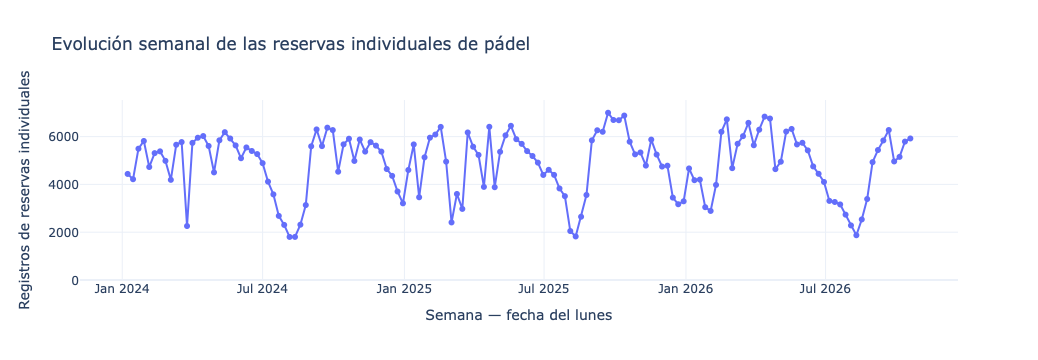

In [11]:
import plotly.express as px

# 1. Asignar cada registro a una semana de lunes a domingo.
# "semana" contiene la fecha del lunes.
reservas["semana"] = (
    reservas["fecha"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

# 2. Contar registros y centros representados en cada semana
resumen_semanal = (
    reservas
    .groupby("semana")
    .agg(
        reservas_registradas=("fecha", "size"),
        centros_con_registros=("Centro deportivo", "nunique"),
        dias_con_registros=("fecha", "nunique")
    )
    .sort_index()
)

# 3. Incluir todas las semanas del intervalo.
# Las semanas sin registros se dejan vacías, no se rellenan con cero.
todas_las_semanas = pd.date_range(
    start=reservas["semana"].min(),
    end=reservas["semana"].max(),
    freq="W-MON"
)

resumen_semanal = (
    resumen_semanal
    .reindex(todas_las_semanas)
    .rename_axis("semana")
    .reset_index()
)

resumen_semanal["fin_semana"] = (
    resumen_semanal["semana"] + pd.Timedelta(days=6)
)

# 4. Marcar las semanas que quedan dentro del intervalo observado.
# Evitamos que los extremos parciales parezcan caídas de reservas.
resumen_semanal["dentro_intervalo_observado"] = (
    (resumen_semanal["semana"] >= reservas["fecha"].min())
    & (resumen_semanal["fin_semana"] <= reservas["fecha"].max())
)

semanas_grafico = resumen_semanal.loc[
    resumen_semanal["dentro_intervalo_observado"]
].copy()

# 5. Crear el gráfico interactivo
fig = px.line(
    semanas_grafico,
    x="semana",
    y="reservas_registradas",
    markers=True,
    title="Evolución semanal de las reservas individuales de pádel",
    labels={
        "semana": "Semana — fecha del lunes",
        "reservas_registradas": "Registros de reservas individuales",
        "centros_con_registros": "Centros con registros",
        "dias_con_registros": "Días con registros"
    },
    hover_data=["centros_con_registros", "dias_con_registros"],
    template="plotly_white"
)

fig.update_traces(connectgaps=False)
fig.update_layout(hovermode="x unified")
fig.update_yaxes(rangemode="tozero")
fig.show()

# 6. Guardar la tabla completa y el gráfico
resumen_semanal.to_csv(
    carpeta_analisis / "reservas_semanales.csv",
    index=False,
    encoding="utf-8-sig"
)

fig.write_html(
    str(carpeta_analisis / "evolucion_semanal.html"),
    include_plotlyjs=True
)

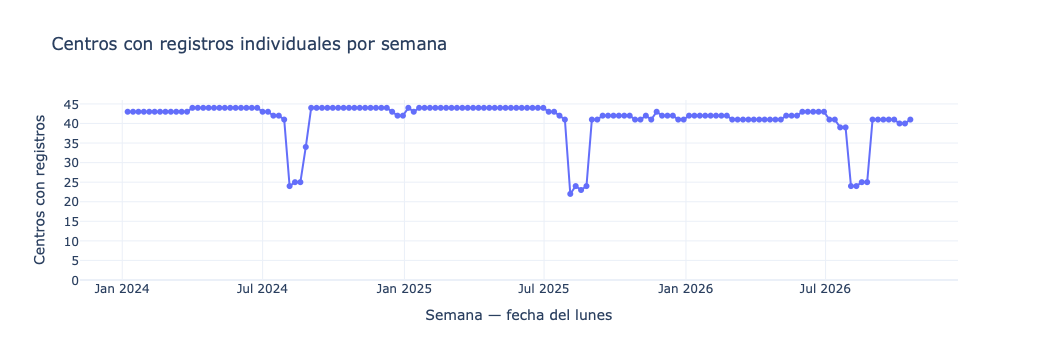

In [12]:
# Complemento del gráfico de reservas:
# número de centros con registros individuales cada semana.

fig_centros = px.line(
    semanas_grafico,
    x="semana",
    y="centros_con_registros",
    markers=True,
    title="Centros con registros individuales por semana",
    labels={
        "semana": "Semana — fecha del lunes",
        "centros_con_registros": "Centros con registros"
    },
    template="plotly_white"
)

fig_centros.update_traces(connectgaps=False)

fig_centros.update_yaxes(
    range=[0, reservas["Centro deportivo"].nunique() + 1],
    dtick=5
)

fig_centros.update_layout(hovermode="x unified")
fig_centros.show()

fig_centros.write_html(
    str(carpeta_analisis / "centros_con_registros_semanales.html"),
    include_plotlyjs=True
)

Número de fechas utilizadas para cada día de la semana:


,fechas_observadas
Lunes,147
Martes,148
Miércoles,143
Jueves,145
Viernes,148
Sábado,148
Domingo,147


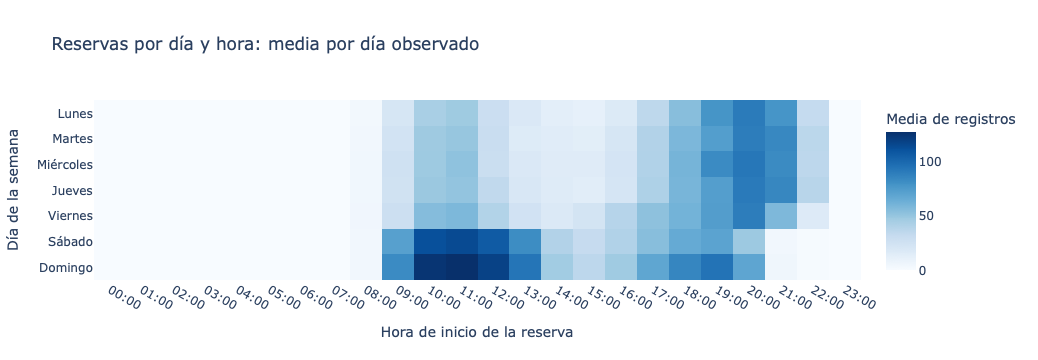

In [13]:
# 1. Preparar fecha y hora de inicio
datos_horarios = reservas.copy()

datos_horarios["fecha_dia"] = (
    datos_horarios["fecha"].dt.normalize()
)

# Agrupar los inicios en intervalos de una hora.
# Ejemplo: 18:00 y 18:30 se incluyen en la franja de las 18.
datos_horarios["hora"] = (
    pd.to_numeric(datos_horarios["hora_inicio_num"], errors="raise")
    // 1
).astype(int)

# 2. Contar los registros por fecha y hora
registros_por_dia_hora = (
    datos_horarios
    .groupby(["fecha_dia", "hora"])
    .size()
    .unstack("hora", fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

# Solo aparecen fechas con algún registro individual.
# Dentro de esas fechas, cero significa que no hay registros
# que comiencen en esa franja horaria.

# 3. Calcular la media para cada día de la semana
mapa_horario = (
    registros_por_dia_hora
    .groupby(registros_por_dia_hora.index.day_of_week)
    .mean()
    .reindex(range(7))
)

dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

mapa_horario.index = dias
mapa_horario.columns = [f"{hora:02d}:00" for hora in range(24)]

# 4. Mostrar cuántas fechas se utilizan para cada media
dias_observados = (
    datos_horarios[["fecha_dia"]]
    .drop_duplicates()
    .assign(dia_semana=lambda x: x["fecha_dia"].dt.day_of_week)
    .groupby("dia_semana")
    .size()
    .reindex(range(7), fill_value=0)
)

dias_observados.index = dias

print("Número de fechas utilizadas para cada día de la semana:")
display(dias_observados.rename("fechas_observadas").to_frame())

# 5. Dibujar el mapa de calor
fig_horario = px.imshow(
    mapa_horario,
    aspect="auto",
    color_continuous_scale="Blues",
    labels={
        "x": "Hora de inicio de la reserva",
        "y": "Día de la semana",
        "color": "Media de registros"
    },
    title="Reservas por día y hora: media por día observado",
    template="plotly_white"
)

fig_horario.update_traces(
    hovertemplate=(
        "%{y}, franja de las %{x}"
        "<br>Media de registros: %{z:.1f}"
        "<extra></extra>"
    )
)

fig_horario.show()

# 6. Guardar resultados
mapa_horario.to_csv(
    carpeta_analisis / "media_reservas_dia_hora.csv",
    index_label="dia_semana",
    encoding="utf-8-sig"
)

fig_horario.write_html(
    str(carpeta_analisis / "mapa_calor_dia_hora.html"),
    include_plotlyjs=True
)

In [14]:
# Variación respecto a la semana anterior
comparacion_semanal = (
    semanas_grafico
    .sort_values("semana")
    .copy()
)

# Recuperar los valores de la semana anterior
comparacion_semanal["reservas_semana_anterior"] = (
    comparacion_semanal["reservas_registradas"].shift(1)
)

comparacion_semanal["centros_semana_anterior"] = (
    comparacion_semanal["centros_con_registros"].shift(1)
)

# Evitar dividir entre cero.
# Si falta el dato anterior, la variación queda vacía.
base_comparacion = comparacion_semanal[
    "reservas_semana_anterior"
].where(
    comparacion_semanal["reservas_semana_anterior"] > 0
)

comparacion_semanal["variacion_pct"] = (
    (
        comparacion_semanal["reservas_registradas"]
        / base_comparacion
    ) - 1
) * 100

comparacion_semanal["cambio_numero_centros"] = (
    comparacion_semanal["centros_con_registros"]
    - comparacion_semanal["centros_semana_anterior"]
)

columnas_mostrar = [
    "semana",
    "reservas_registradas",
    "reservas_semana_anterior",
    "variacion_pct",
    "centros_con_registros",
    "cambio_numero_centros"
]

display(
    comparacion_semanal[columnas_mostrar]
    .tail(12)
    .round({"variacion_pct": 2})
)

comparacion_semanal.to_csv(
    carpeta_analisis / "comparacion_semanal.csv",
    index=False,
    encoding="utf-8-sig"
)

,semana,reservas_registradas,reservas_semana_anterior,variacion_pct,centros_con_registros,cambio_numero_centros
135,2026-08-03,2284,2735.0,-16.49,24,-15.0
136,2026-08-10,1873,2284.0,-17.99,24,0.0
137,2026-08-17,2534,1873.0,35.29,25,1.0
138,2026-08-24,3388,2534.0,33.70,25,0.0
139,2026-08-31,4931,3388.0,45.54,41,16.0
140,2026-09-07,5438,4931.0,10.28,41,0.0
141,2026-09-14,5839,5438.0,7.37,41,0.0
142,2026-09-21,6275,5839.0,7.47,41,0.0
143,2026-09-28,4961,6275.0,-20.94,41,0.0
144,2026-10-05,5152,4961.0,3.85,40,-1.0


In [15]:
# Preparar los datos que utilizará la aplicación Dash.
# "reservas" ya debe tener los nombres de centros normalizados.

carpeta_app = Path("Datos/app")
carpeta_app.mkdir(parents=True, exist_ok=True)

# Conservar únicamente las columnas necesarias para la aplicación.
datos_app = reservas[
    [
        "fecha",
        "Centro deportivo",
        "hora_inicio_num",
        "duracion_minutos"
    ]
].copy()

datos_app = datos_app.sort_values(
    ["fecha", "Centro deportivo", "hora_inicio_num"]
)

archivo_app = carpeta_app / "reservas_padel_app.csv"

datos_app.to_csv(
    archivo_app,
    index=False,
    encoding="utf-8-sig"
)

print("Registros exportados:", len(datos_app))
print("Centros:", datos_app["Centro deportivo"].nunique())
print("Primera fecha:", datos_app["fecha"].min())
print("Última fecha:", datos_app["fecha"].max())
print("Tamaño del archivo (MB):", round(
    archivo_app.stat().st_size / (1024 ** 2), 2
))
print("Archivo guardado en:", archivo_app.resolve())

Registros exportados: 719178
Centros: 45
Primera fecha: 2024-01-02 00:00:00
Última fecha: 2026-10-31 00:00:00
Tamaño del archivo (MB): 24.32
Archivo guardado en: /home/202207424/TFG analytics/Datos/app/reservas_padel_app.csv
